[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jeremydwong/bonelab_inverse_dynamics/blob/main/notebooks/tutorial_s2s_markers.ipynb)

# Squat-to-stand from c3d files: the real pipeline on a body where every answer is known

> **Why you can trust this page:** the idealized subject goes through the
> *exact same pipeline* we use on real, non-idealized people: the same
> functions, the same calls, the same settings, copied cell for cell from the
> Asics running notebook. The only thing that changes is the subject. So when
> the answer comes out right here, that should give us significant confidence
> in the numbers we get on a real runner. Whatever differs there comes from
> the person (skin motion, marker noise, joint-centre guesses), not from the
> code.

We are going to demonstrate the following key steps in the inverse dynamics workflow:

1. Record an idealized person as the files a lab would hand you: a static c3d and a squat c3d with one force plate (step 3).
2. Run the Asics calls on them, unchanged: load, calibrate, build the chain, check the marker fit, solve, audit energy (steps 4–11).
3. Check the calibration rebuilt the true body (step 12).
4. Compare the torques with a top-down truth, then read the residual and the energy audit (step 13).
5. Watch it (step 14).
6. Switch the legacy MATLAB's 3-D errors back on and see what each costs (step 15).
7. Add 1 mm of marker noise and see why there's a filter cutoff at all (step 16).

This notebook reports on the following key findings about our reanalysis:

1. Calibration from the static markers rebuilds the simulator's body: max mass error 0.0 kg, COM error 1.6e-08 m, inertia error 1.5e-07 kg m² (step 12).
2. File to torque, the pipeline lands on the truth: worst joint torque error 0.027 N m (ankle) against peaks of 113.2–160.7 N m, worst joint force error 0.023 N, with the 12 Hz filters on (step 13).
3. The residual at the top of the torso is basically zero: max 0.025 N and 0.009 N m, with 551.4 N standing on the plate (step 13).
4. The energy audit closes: peak imbalance 1.2e-02 W against 598 W peak dE/dt, and integrating the joint powers over the rise gives back the energy change, 352.716 J vs 352.717 J (step 13).
5. Of the two legacy 3-D errors, the one-sided inertia $R\,I$ costs 1.156 N m on the swaying squat and 1.155 N m on the planar one, so planar doesn't forgive it; the missing gyroscopic term costs nothing measurable on a squat this slow (step 15).
6. With 1 mm marker noise, the unfiltered torques are off by up to 737.8 N m; the Asics 12 Hz cutoff brings that to 7.6 N m (step 16).

Chapter 2, the real pipeline on an idealized person. Previous: [two bricks](tutorial_two_bricks_2d.ipynb).
Next: [6-DoF joint power](tutorial_6dof.ipynb), the same body with a knee that slides.

**The body.** One right leg (de Leva foot, shank, thigh), a pelvis and a
torso (de Leva trunk + head) of an 80 kg person. That's it: no left leg, no
arms. Ideal joints, markers that never slide, a plate with no noise. The
torso leans sideways and back as it rises, so the motion is 3-D. The markers
are the Asics markerset, plus one thing the Asics lab didn't have: torso
markers (C7, CLAV, STRN, T10 and the acromions). When the static trial has
them, `build_chain` adds the torso as a fifth segment and L5/S1 becomes a
real joint. Nothing acts above the torso, so the residual should be **zero**.
(On the real runner the chain stops at the pelvis and the residual there is
the whole upper body.)

In [1]:
# Colab bootstrap — a no-op when running locally in the uv environment.
import os, sys, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "boneid @ git+https://github.com/jeremydwong/bonelab_inverse_dynamics"],
                   check=True)
os.makedirs("../reports", exist_ok=True)

## 1 — Import the analysis tools

Same imports as the Asics notebook, plus the simulator.

In [2]:
from pathlib import Path
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import numpy as np

from boneid.core import AnalysisParams, energy_audit, inverse_dynamics
from boneid.io_c3d import build_chain, calibrate_static, load_c3d
from boneid.report import c3d_report_html, c3d_viewer_html, right_step_events

# The report module selects Agg for file rendering; restore notebook figure output.
%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
print(f"Repository: {ROOT}")

from boneid.simulate import simulate_squat_to_stand_c3d

Repository: /Users/jeremy/Git/brent/bonelab_inverse_dynamics


## 2 — Choose the study settings

Same names as the Asics notebook. What differs: where the files live and what
they're called, the body mass, and one knob only the simulator reads (how far
the torso sways).

About `BODY_MASS_KG`: in the Asics notebook it's `None`, meaning "weigh the
subject on the static plate". That doesn't work here, because this person has
no left leg and no arms, so the plate only sees ~56 kg. The de Leva fractions
are fractions of the *whole* person, so I tell it 80 kg, like you would from
a scale.

In [3]:
DATA_DIR = ROOT / "data" / "simulated"
SUBJECT = "SIM"
CONDITION = "S2S"
TRIAL = "RISE"
SEX = "male"
BODY_MASS_KG = 80.0             # the whole person, as from a scale
CONTACT_THRESHOLD_N = 50.0
KINEMATIC_LOWPASS_HZ = 12.0
TREADMILL_ORIGIN = np.zeros(3)

TORSO_SWAY_RAD = 0.25           # simulator only: makes the motion 3-D

print(f"Static: {DATA_DIR / f'{SUBJECT}_{CONDITION}_Static.c3d'}")
print(f"Dynamic: {DATA_DIR / f'{SUBJECT}_{CONDITION}_{TRIAL}.c3d'}")

Static: /Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/simulated/SIM_S2S_Static.c3d
Dynamic: /Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/simulated/SIM_S2S_RISE.c3d


## 3 — Record the idealized subject as two c3d files

The only step the Asics notebook doesn't have (there, the lab did it).
`simulate_squat_to_stand_c3d` scripts the motion at 3000 Hz, gets the floor's
wrench from whole-body Newton–Euler, and writes markers at 300 Hz and one
force plate at 3000 Hz, like the Asics study. The medial ankle and knee
markers are only in the static file, like the real thing, so the joint
centres have to be carried by the cluster fits.

It also hands back `truth`: joint forces and torques computed **top-down**
(each joint carries everything above it), which never touches the pipeline's
bottom-up recursion. We don't look at `truth` again until step 12.

In [4]:
truth = simulate_squat_to_stand_c3d(DATA_DIR, subject=SUBJECT, condition=CONDITION,
                                    trial=TRIAL, body_mass=BODY_MASS_KG,
                                    torso_sway=TORSO_SWAY_RAD, sex=SEX)
print(truth["static_path"]); print(truth["dynamic_path"])
print(f"body mass {truth['body_mass']:.0f} kg; what's actually standing on the plate: "
      f"{truth['plate_mass']:.1f} kg (right leg + pelvis + torso)")

/Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/simulated/SIM_S2S_Static.c3d
/Users/jeremy/Git/brent/bonelab_inverse_dynamics/data/simulated/SIM_S2S_RISE.c3d
body mass 80 kg; what's actually standing on the plate: 56.2 kg (right leg + pelvis + torso)


## 4 — Load the standing trial

From here through step 11 the code cells are the Asics notebook's, unchanged.

In [5]:
static = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_Static.c3d")
display({"type": type(static).__name__, "motion_frames": len(static.t),
         "motion_rate_hz": static.rate, "analog_rate_hz": static.analog_rate,
         "marker_count": len(static.markers), "force_shape_Ta_P_xyz": static.force.shape})

{'type': 'C3dTrial',
 'motion_frames': 300,
 'motion_rate_hz': 300.0,
 'analog_rate_hz': 3000.0,
 'marker_count': 28,
 'force_shape_Ta_P_xyz': (3000, 1, 3)}

## 5 — Calibrate the subject

Lengths come from the static markers and should come out as the simulator's
(shank 0.43 m, thigh 0.45 m, torso 0.50 m). Body mass is the 80 kg we passed in.

In [6]:
cal = calibrate_static(static, sex=SEX, body_mass=BODY_MASS_KG)
display({"type": type(cal).__name__, "side": cal.side,
         "body_mass_kg": cal.body_mass, "segment_lengths_m": cal.lengths,
         "joint_centers_and_endpoints_m": cal.points})

{'type': 'StaticCalibration',
 'side': 'r',
 'body_mass_kg': 80.0,
 'segment_lengths_m': {'foot': 0.260000000000001,
  'shank': 0.43000000402659233,
  'thigh': 0.4499999701642309,
  'pelvis': 0.11000002664016757,
  'forefoot_width': 0.07000000000000024,
  'torso': 0.4999999753634077},
 'joint_centers_and_endpoints_m': {'ankle': array([-0.064,  0.   ,  0.08 ]),
  'knee': array([-0.064     , -0.01289806,  0.50980652]),
  'hip': array([-6.40000000e-02,  5.99910021e-04,  9.59604004e-01]),
  'hip_l': array([6.40000000e-02, 5.99910021e-04, 9.59604004e-01]),
  'mid_hip': array([0.00000000e+00, 5.99910021e-04, 9.59604004e-01]),
  'l5s1': array([ 0.        , -0.00159995,  1.06958203]),
  'heel': array([-0.064,  0.06 ,  0.03 ]),
  'toe': array([-0.064, -0.13 ,  0.02 ]),
  'toebox': array([-0.064, -0.2  ,  0.03 ]),
  'mid_acromion': array([ 0.        , -0.00659986,  1.56955701])}}

## 6 — Load the squat trial

In [7]:
trial = load_c3d(DATA_DIR / f"{SUBJECT}_{CONDITION}_{TRIAL}.c3d")
display({"type": type(trial).__name__, "motion_frames": len(trial.t),
         "motion_rate_hz": trial.rate, "analog_rate_hz": trial.analog_rate,
         "force_shape_Ta_P_xyz": trial.force.shape,
         "marker_names": sorted(trial.markers)})  

{'type': 'C3dTrial',
 'motion_frames': 900,
 'motion_rate_hz': 300.0,
 'analog_rate_hz': 3000.0,
 'force_shape_Ta_P_xyz': (9000, 1, 3),
 'marker_names': ['AnkleLat',
  'C7',
  'CLAV',
  'DorsalFoot',
  'HeelLat',
  'HeelMed',
  'KneeLat',
  'LAC',
  'LASIS',
  'LGT',
  'LPSIS',
  'MTP1Head',
  'MTP5Head',
  'RAC',
  'RASIS',
  'RGT',
  'RPSIS',
  'STRN',
  'ShankAntProx',
  'ShankPostDist',
  'ShankPostProx',
  'T10',
  'ThighAntProx',
  'ThighPostDist',
  'ThighPostProx',
  'ToeboxAnt']}

## 7 — Set the analysis parameters

The Asics settings: 12 Hz on both forces and kinematics. (Step 16 is why.)

In [8]:
params = AnalysisParams(contact_threshold_n=CONTACT_THRESHOLD_N,
                        lowpass_hz=KINEMATIC_LOWPASS_HZ,
                        force_lowpass_hz=KINEMATIC_LOWPASS_HZ)
display(params)

AnalysisParams(gravity=array([ 0.  ,  0.  , -9.81]), contact_threshold_n=50.0, lowpass_hz=12.0, force_lowpass_hz=12.0, filter_order=4, treadmill_speed=0.0, flag_crossover=False)

## 8 — Build the right-leg chain

Same call. Behind it: SVD cluster fits, virtual joint centres, de Leva from
the static lengths, and the plate turned into a wrench about the lab origin.
Because the static trial marked the torso, you get five segments and four
joints (ankle, knee, hip, L5/S1) instead of the Asics four and three.

In [9]:
skeleton, kin, ground, quality = build_chain(
    trial, cal, point=TREADMILL_ORIGIN, threshold_n=CONTACT_THRESHOLD_N)
display({"segments": skeleton.segment_names, "joints": skeleton.joint_names,
         "segment_mass_kg": skeleton.mass, "segment_length_m": skeleton.length,
         "kin_r_world_shape_T_S_3_3": kin.r_world.shape,
         "ground_force_shape_T_xyz": ground.force.shape,
         "ground_moment_shape_T_xyz": ground.moment.shape,
         "quality_fields": list(quality)})

{'segments': ['foot', 'shank', 'thigh', 'pelvis', 'torso'],
 'joints': ['ankle', 'knee', 'hip', 'l5s1'],
 'segment_mass_kg': array([ 1.096,  3.464, 11.328,  8.936, 31.384]),
 'segment_length_m': array([0.26      , 0.43      , 0.44999997, 0.11000003, 0.49999998]),
 'kin_r_world_shape_T_S_3_3': (900, 5, 3, 3),
 'ground_force_shape_T_xyz': (900, 3),
 'ground_moment_shape_T_xyz': (900, 3),
 'quality_fields': ['cluster_residual', 'bouts', 'points']}

## 9 — Check the marker fit and the contact

The markers are perfectly rigid, so the cluster-fit residual should be
basically zero (it's float32 rounding in the c3d file, well under a
micrometre), torso included. There's one contact, the whole trial, and it
should be assigned to the right foot.

In [10]:
display({"mean_cluster_residual_mm": dict(zip(
    skeleton.segment_names, 1000 * np.nanmean(quality["cluster_residual"], axis=0)))})
display(quality["bouts"][:5])

{'mean_cluster_residual_mm': {'foot': np.float64(1.501780347440467e-13),
  'shank': np.float64(4.483638240290673e-06),
  'thigh': np.float64(1.1615584643474132e-05),
  'pelvis': np.float64(1.652438009670653e-05),
  'torso': np.float64(2.7788840340160144e-05)}}

[{'plate': 0,
  't_on': np.float64(0.0),
  't_off': np.float64(2.9996666666666667),
  'mine': True,
  'cop_dist_m': 0.10209890758161033}]

## 10 — Solve inverse dynamics

In [11]:
idres = inverse_dynamics(skeleton, kin, ground, params)
display({"type": type(idres).__name__,
         "joint_force_shape_T_J_xyz_N": idres.joint_force.shape,
         "joint_torque_shape_T_J_xyz_Nm": idres.joint_torque.shape,
         "residual_force_shape_T_xyz_N": idres.residual_force.shape})

{'type': 'InverseDynamicsResult',
 'joint_force_shape_T_J_xyz_N': (900, 4, 3),
 'joint_torque_shape_T_J_xyz_Nm': (900, 4, 3),
 'residual_force_shape_T_xyz_N': (900, 3)}

## 11 — Audit energy balance

In [12]:
audit = energy_audit(skeleton, kin, ground, idres, params)
edge = slice(int(kin.rate), -int(kin.rate))
display({"type": type(audit).__name__, "energy_shape_T": audit.kinetic.shape,
         "joint_power_shape_T_J": audit.joint_power.shape,
         "interior_imbalance_rms_W": float(np.sqrt(np.mean(audit.imbalance[edge] ** 2))),
         "interior_imbalance_peak_abs_W": float(np.max(np.abs(audit.imbalance[edge])))})

{'type': 'EnergyAudit',
 'energy_shape_T': (900,),
 'joint_power_shape_T_J': (900, 4),
 'interior_imbalance_rms_W': 0.005354027734356297,
 'interior_imbalance_peak_abs_W': 0.011539853335648331}

## 12 — Did calibration rebuild the true body?

Before comparing torques, check the inputs: the skeleton `build_chain` made
from the markers against the one the simulator used.

In [13]:
sk_true = truth["skeleton"]
display({"segment_mass_kg (pipeline)": dict(zip(skeleton.segment_names, skeleton.mass.round(4))),
         "max |mass error| kg": float(np.abs(skeleton.mass - sk_true.mass).max()),
         "max |COM error| m": float(np.abs(skeleton.com_local - sk_true.com_local).max()),
         "max |inertia error| kg m^2": float(np.abs(skeleton.inertia_local - sk_true.inertia_local).max())})

{'segment_mass_kg (pipeline)': {'foot': np.float64(1.096),
  'shank': np.float64(3.464),
  'thigh': np.float64(11.328),
  'pelvis': np.float64(8.936),
  'torso': np.float64(31.384)},
 'max |mass error| kg': 0.0,
 'max |COM error| m': 1.6290462465096134e-08,
 'max |inertia error| kg m^2': 1.4715667329134874e-07}

## 13 — Compare with the truth: torques, residual, energy

Now the actual test. Solid lines are the pipeline, dashed are the top-down
truth. I plot lab X (the sagittal component in this lab, same as the Asics
plots), then the error on all three components. The first and last 50 ms are
left out because the filters have edge effects there.

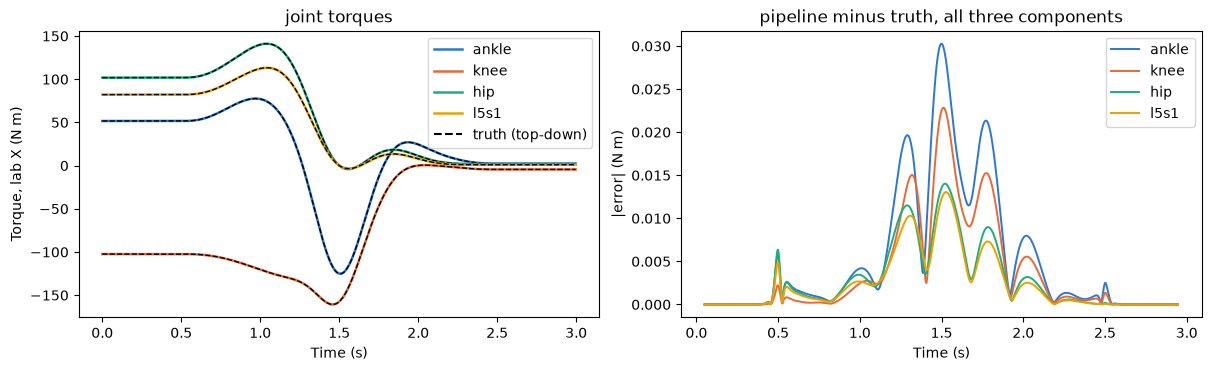

{'ankle': {'peak |torque| N m': 125.2,
  'max torque error N m': 0.02730049303984572,
  'max force error N': 0.02258394815031295},
 'knee': {'peak |torque| N m': 160.7,
  'max torque error N m': 0.020308400710774777,
  'max force error N': 0.02265062733816592},
 'hip': {'peak |torque| N m': 141.1,
  'max torque error N m': 0.01100895090570031,
  'max force error N': 0.020225887610465065},
 'l5s1': {'peak |torque| N m': 113.2,
  'max torque error N m': 0.009772406579739545,
  'max force error N': 0.017473598143865843}}

In [14]:
from boneid.report import JOINT_COLORS

inner = slice(15, -15)
t = idres.t
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), layout="constrained")
for j, name in enumerate(skeleton.joint_names):
    axes[0].plot(t, idres.joint_torque[:, j, 0], color=JOINT_COLORS[j], lw=1.8, label=name)
    axes[0].plot(t, truth["joint_torque"][:, j, 0], color="k", lw=1.0, ls="--")
    axes[1].plot(t[inner], np.linalg.norm(idres.joint_torque[inner, j] - truth["joint_torque"][inner, j], axis=1),
                 color=JOINT_COLORS[j], lw=1.4, label=name)
axes[0].plot([], [], color="k", ls="--", label="truth (top-down)")
axes[0].set(xlabel="Time (s)", ylabel="Torque, lab X (N m)", title="joint torques")
axes[1].set(xlabel="Time (s)", ylabel="|error| (N m)", title="pipeline minus truth, all three components")
axes[0].legend(); axes[1].legend()
plt.show()

err_t = np.abs(idres.joint_torque[inner] - truth["joint_torque"][inner]).max(axis=(0, 2))
err_f = np.abs(idres.joint_force[inner] - truth["joint_force"][inner]).max(axis=(0, 2))
peak = np.abs(truth["joint_torque"]).max(axis=(0, 2))
display({name: {"peak |torque| N m": round(float(p), 1), "max torque error N m": float(et),
                "max force error N": float(ef)}
         for name, p, et, ef in zip(skeleton.joint_names, peak, err_t, err_f)})

### The residual is zero

Nothing acts above the torso, so whatever's left over at the top of the chain
is error. On a real person this is where soft tissue and model mistakes show
up. Here it should be basically nothing.

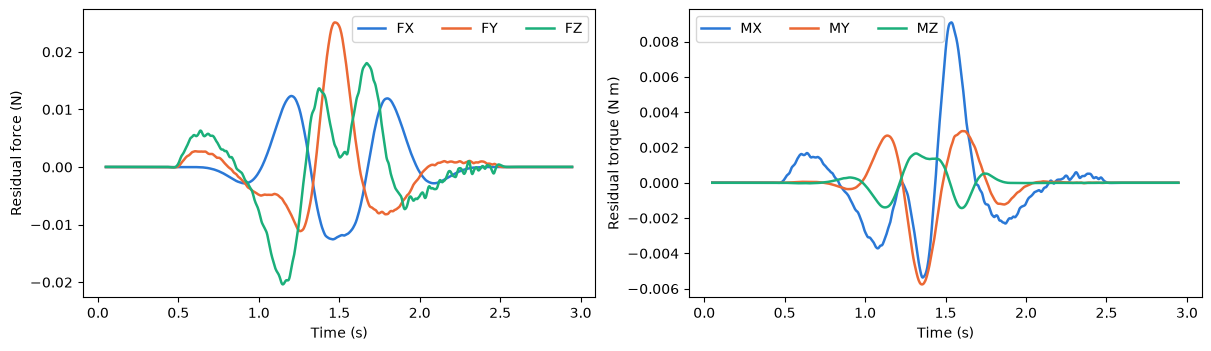

{'weight on the plate N': 551.4,
 'max |residual force| N': 0.025110095659414355,
 'max |residual torque| N m': 0.009082473823333662}

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), layout="constrained")
for c, lab in enumerate("XYZ"):
    axes[0].plot(t[inner], idres.residual_force[inner, c], color=JOINT_COLORS[c], lw=1.8, label=f"F{lab}")
    axes[1].plot(t[inner], idres.residual_torque[inner, c], color=JOINT_COLORS[c], lw=1.8, label=f"M{lab}")
axes[0].set(xlabel="Time (s)", ylabel="Residual force (N)")
axes[1].set(xlabel="Time (s)", ylabel="Residual torque (N m)")
axes[0].legend(ncol=3); axes[1].legend(ncol=3)
plt.show()
display({"weight on the plate N": round(truth["plate_mass"] * 9.81, 1),
         "max |residual force| N": float(np.abs(idres.residual_force[inner]).max()),
         "max |residual torque| N m": float(np.abs(idres.residual_torque[inner]).max())})

### The energy audit closes

Same audit as always. On a real runner the imbalance is ~1–2% of peak; here
it should be basically nothing.

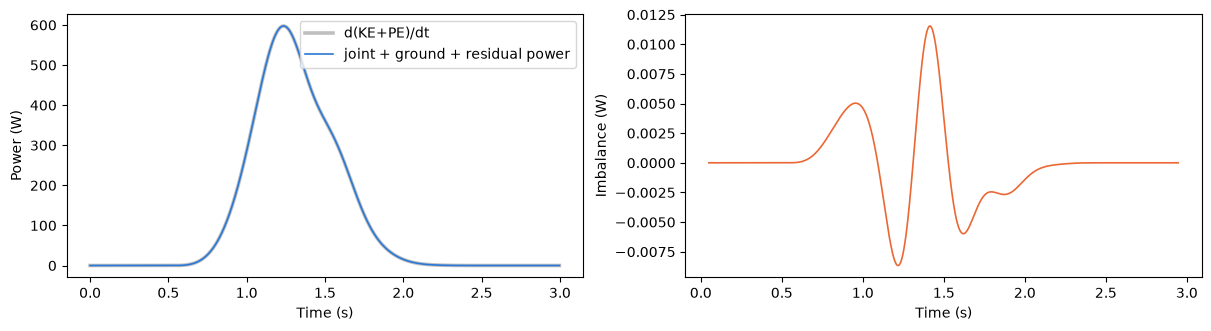

peak imbalance 1.2e-02 W of 598 W peak dE/dt


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2), layout="constrained")
axes[0].plot(t, audit.de_dt, color="gray", lw=2.6, alpha=0.5, label="d(KE+PE)/dt")
axes[0].plot(t, audit.power_total, color=JOINT_COLORS[0], lw=1.2, label="joint + ground + residual power")
axes[0].set(xlabel="Time (s)", ylabel="Power (W)"); axes[0].legend()
axes[1].plot(t[inner], audit.imbalance[inner], color=JOINT_COLORS[1], lw=1.2)
axes[1].set(xlabel="Time (s)", ylabel="Imbalance (W)")
plt.show()
print(f"peak imbalance {np.abs(audit.imbalance[inner]).max():.1e} W of "
      f"{np.abs(audit.de_dt).max():.0f} W peak dE/dt")

### Where the energy goes

One more way to see that the books balance. The foot never moves and nothing
acts above the torso, so the only things that can change the body's energy
are the joints. Add up the joint powers, integrate over the rise, and you
should get back exactly the change in kinetic + potential energy. Below: the
energies, the plate force that lifts them (the dip is the unweighting at the
start, the bump is pushing up), and each joint's power.

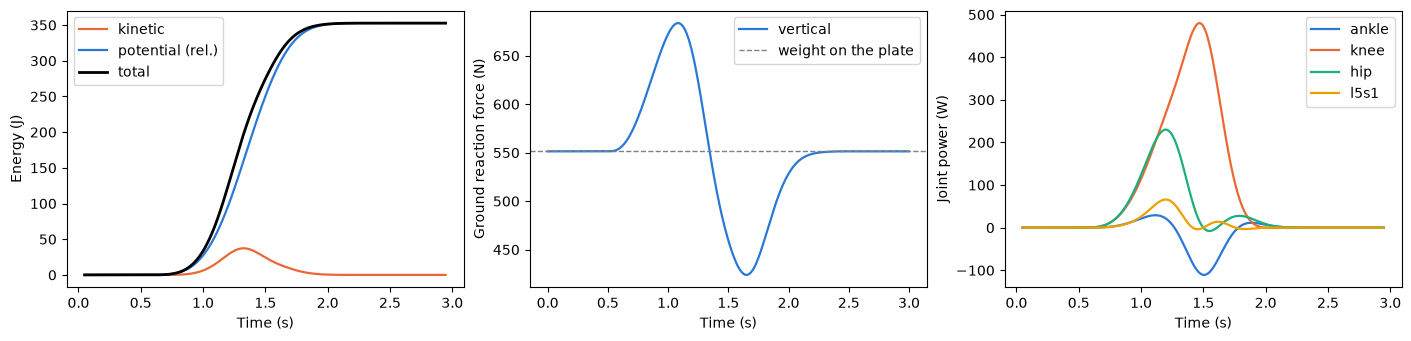

integral of joint power 352.716 J; change in KE + PE 352.717 J (difference -7.77e-04 J)


In [17]:
pe0 = audit.potential[inner][0]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.3), layout="constrained")
axes[0].plot(t[inner], audit.kinetic[inner], color=JOINT_COLORS[1], lw=1.6, label="kinetic")
axes[0].plot(t[inner], audit.potential[inner] - pe0, color=JOINT_COLORS[0], lw=1.6, label="potential (rel.)")
axes[0].plot(t[inner], (audit.kinetic + audit.potential)[inner] - pe0, color="k", lw=2.0, label="total")
axes[0].set(xlabel="Time (s)", ylabel="Energy (J)"); axes[0].legend()
axes[1].plot(t, ground.force[:, 2], color=JOINT_COLORS[0], lw=1.6, label="vertical")
axes[1].axhline(truth["plate_mass"] * 9.81, color="gray", lw=1.0, ls="--", label="weight on the plate")
axes[1].set(xlabel="Time (s)", ylabel="Ground reaction force (N)"); axes[1].legend()
for j, name in enumerate(skeleton.joint_names):
    axes[2].plot(t[inner], audit.joint_power[inner, j], color=JOINT_COLORS[j], lw=1.6, label=name)
axes[2].set(xlabel="Time (s)", ylabel="Joint power (W)"); axes[2].legend()
plt.show()

work = np.trapezoid(audit.joint_power[inner].sum(axis=1), t[inner])
de = float((audit.kinetic + audit.potential)[inner][-1] - (audit.kinetic + audit.potential)[inner][0])
print(f"integral of joint power {work:.3f} J; change in KE + PE {de:.3f} J (difference {work - de:+.2e} J)")

So the whole pipeline, c3d file to joint torque, lands on the truth to a few
hundredths of a N m against peaks of 100+ N m, and that's with the 12 Hz
filters on. This is also the KEY test `KEY-S2S-C3D` (`tests/test_key.py`), so
if the loader, calibration, cluster fits, plate handling or recursion ever
breaks, the test suite says so.

## 14 — Watch it

The same viewer the Asics report uses.

In [18]:
viewer_html = c3d_viewer_html(trial, cal, skeleton, kin, ground, quality, params)
display(HTML(viewer_html))

## 15 — What the legacy 3-D errors cost here

The old MATLAB got Euler's equation wrong twice: a one-sided inertia
transform ($R\,I$ instead of $R\,I\,R^{\mathsf T}$) and no gyroscopic term
$\omega\times(I\omega)$. `LegacyPhysics` switches either back on inside the
same recursion. I run it on the swaying (3-D) recording and on the same squat
recorded with no sway (planar), same calls.

How I read the table:

* **No gyroscopic term costs nothing measurable here, even in 3-D.** It grows
  with angular velocity squared, and a 2-second squat is slow.
* **One-sided inertia costs ~1 N m, planar or not.** Planar only forgives it
  when the lab axis you rotate about is also the segment's own axis with the
  same name. Here the squat rotates about lab x (subject left) but each
  segment's own x points forward, so $R\,I$ reads the wrong row of the inertia
  tensor. It isn't a tensor transform, so the answer depends on how you set up
  your lab.

Both are small next to 100+ N m, but the one-sided inertia isn't noise: the
correct physics sits at a few hundredths. The math is in
[the legacy-error notebook](legacy_error_math.ipynb); the guarding test is `KEY-GYRO`.

In [19]:
from boneid.core import LegacyPhysics

def run_pipeline(condition, **sim):
    """The Asics calls, start to finish, on a freshly written recording."""
    tr = simulate_squat_to_stand_c3d(DATA_DIR, subject=SUBJECT, condition=condition,
                                     trial=TRIAL, body_mass=BODY_MASS_KG, sex=SEX, **sim)
    st = load_c3d(DATA_DIR / f"{SUBJECT}_{condition}_Static.c3d")
    cl = calibrate_static(st, sex=SEX, body_mass=BODY_MASS_KG)
    dy = load_c3d(DATA_DIR / f"{SUBJECT}_{condition}_{TRIAL}.c3d")
    sk, kn, gr, _ = build_chain(dy, cl, point=TREADMILL_ORIGIN, threshold_n=CONTACT_THRESHOLD_N)
    return tr, sk, kn, gr

variants = {
    "correct physics": None,
    "one-sided inertia  R·I": LegacyPhysics(one_sided_inertia=True),
    "no gyroscopic term": LegacyPhysics(gyroscopic=False),
    "both legacy errors": LegacyPhysics(one_sided_inertia=True, gyroscopic=False),
}
planar = run_pipeline(f"{CONDITION}PLANAR", torso_sway=0.0)
rows = {}
for label, phys in variants.items():
    err = []
    for tr, sk, kn, gr in ((truth, skeleton, kin, ground), planar):
        r = inverse_dynamics(sk, kn, gr, params, physics=phys)
        err.append(float(np.abs(r.joint_torque[inner] - tr["joint_torque"][inner]).max()))
    rows[label] = {"max torque error, 3-D (N m)": round(err[0], 3),
                   "max torque error, planar (N m)": round(err[1], 3)}
display(rows)

{'correct physics': {'max torque error, 3-D (N m)': 0.027,
  'max torque error, planar (N m)': 0.006},
 'one-sided inertia  R·I': {'max torque error, 3-D (N m)': 1.156,
  'max torque error, planar (N m)': 1.155},
 'no gyroscopic term': {'max torque error, 3-D (N m)': 0.027,
  'max torque error, planar (N m)': 0.006},
 'both legacy errors': {'max torque error, 3-D (N m)': 1.068,
  'max torque error, planar (N m)': 1.068}}

## 16 — Why step 7 has a filter cutoff: 1 mm of marker noise

Everything above had perfect markers. Now record the same squat with 1 mm of
Gaussian noise on every marker (a good optical system on a calm day) and run
the same calls twice: no filter, and the Asics 12 Hz. Two derivatives of a
noisy position give accelerations that are mostly noise, and the torques
inherit it (the legend has the max error over all joints). I think of the
cutoff as the place where you decide how much of the signal's bandwidth you
actually believe.

no filter: max joint torque error 737.8 N m
12 Hz low-pass: max joint torque error 7.6 N m


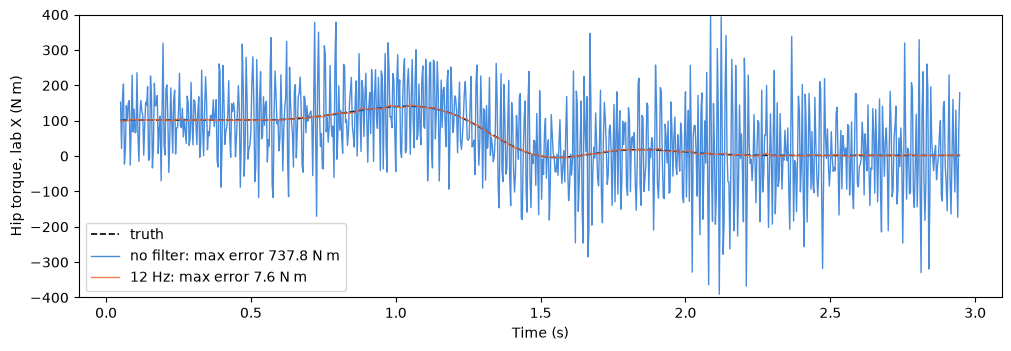

In [20]:
noisy = run_pipeline(f"{CONDITION}NOISY", torso_sway=TORSO_SWAY_RAD, marker_noise_m=0.001)
tr_n, sk_n, kn_n, gr_n = noisy
fig, ax = plt.subplots(figsize=(10, 3.4), layout="constrained")
ax.plot(t[inner], tr_n["joint_torque"][inner, 2, 0], color="k", lw=1.2, ls="--", label="truth")
for k, cutoff in enumerate((0.0, 12.0)):
    p = AnalysisParams(contact_threshold_n=CONTACT_THRESHOLD_N, lowpass_hz=cutoff, force_lowpass_hz=cutoff)
    r = inverse_dynamics(sk_n, kn_n, gr_n, p)
    e = np.abs(r.joint_torque[inner] - tr_n["joint_torque"][inner]).max()
    ax.plot(t[inner], r.joint_torque[inner, 2, 0], color=JOINT_COLORS[k], lw=1.0, alpha=0.85,
            label=f"{'no filter' if cutoff == 0 else f'{cutoff:.0f} Hz'}: max error {e:.1f} N m")
    print(f"{'no filter' if cutoff == 0 else f'{cutoff:.0f} Hz low-pass'}: max joint torque error {e:.1f} N m")
ax.set(xlabel="Time (s)", ylabel="Hip torque, lab X (N m)", ylim=(-400, 400))
ax.legend()
plt.show()

## Where this leaves you

You've run the real pipeline, file to torque, on a body where every answer was
known: the torques landed on the truth, the residual was zero, the energy audit
closed. You've also seen what a legacy term and a noisy marker do to those numbers.

Next: [6-DoF joint power](tutorial_6dof.ipynb), same body, same pipeline, a
knee that slides. Or jump to the [Asics running notebook](asics_running_c3d.ipynb),
which is this page's code on a real runner =)